# 25.43 Laboratorio de Procesamiento de Señales — Del tiempo-frecuencia a los bancos de filtros

Clase 7. **No se entrega.**

Cada experimento arranca con una pregunta. **Escribí tu respuesta antes de correr la celda.**

Lo que importa no es el gráfico: es la diferencia entre lo que esperabas y lo que salió.

---

## Cómo se usa

Se usa el registro de H1 que ya usaste en el TP1. La celda de carga se encarga: busca el
archivo de 32 s donde lo dejó el TP1 (`tps/datos/`), junto a esta notebook o en `./datos/`, y
si no lo encuentra lo baja de GWOSC —son 1 MB— y lo guarda en `./datos/`.

Corré las dos celdas de abajo primero. Después, cada experimento en orden.

Si algo no corre, Discord.

In [3]:
%matplotlib widget

import os
import urllib.request

import numpy as np
import matplotlib.pyplot as plt
from scipy import signal
import h5py  # los registros de GWOSC son HDF5 — si falta:  pip install h5py

plt.rcParams["figure.figsize"] = (11, 3.6)
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.3

rng = np.random.default_rng(2543)

print("Listo.")

Listo.


---

## La cadena del TP1, en una celda

Todo esto ya lo hiciste: cargar, estimar la PSD sobre tramos sin evento, blanquear, pasabanda,
recortar los bordes. Acá va condensado, porque hoy es el punto de partida y no el trabajo.

El control de sanidad es el del TP: el registro blanqueado tiene **desvío ≈ 1** lejos del evento.

In [4]:
GPS_EVENTO = 1126259462.4
GPS0, SEGUNDOS = 1126259447, 32  # la ventana corta que GWOSC publica alrededor de GW150914

GWOSC = "https://gwosc.org/eventapi/json/GWTC-1-confident/GW150914/v3/"
ARCHIVO = f"H-H1_GWOSC_4KHZ_R1-{GPS0}-{SEGUNDOS}.hdf5"
# donde buscarlo antes de bajarlo: el ./datos/ de esta notebook, junto a la notebook,
# y el del TP1 — el archivo es el mismo, no hay por qué bajarlo dos veces
CANDIDATOS = ["datos", ".", "../../tps/datos"]


def _bajar(ruta):
    """Baja a un .parcial y recién ahí renombra: una descarga cortada no deja un
    archivo trunco haciéndose pasar por bueno."""
    os.makedirs(os.path.dirname(ruta) or ".", exist_ok=True)
    parcial = ruta + ".parcial"
    print(f"Bajando {ARCHIVO} de GWOSC...")
    try:
        urllib.request.urlretrieve(GWOSC + ARCHIVO, parcial)
    except BaseException:
        if os.path.exists(parcial):
            os.remove(parcial)
        raise
    os.replace(parcial, ruta)  # si había una copia dañada, esto la reemplaza
    print(f"  guardado: {ruta}  ({os.path.getsize(ruta) / 1e6:.1f} MB)")


def cargar_h1():
    """Devuelve (strain, fs, t_evento), con t_evento medido desde el inicio del
    registro. La primera vez baja el archivo de GWOSC a ./datos/ si no lo
    encuentra en ningún candidato; de ahí en más lo lee del disco."""
    ruta = next((os.path.join(d, ARCHIVO) for d in CANDIDATOS
                 if os.path.exists(os.path.join(d, ARCHIVO))), None)

    for intento in (1, 2):
        if ruta is None:
            ruta = os.path.join("datos", ARCHIVO)
            try:
                _bajar(ruta)
            except Exception as e:
                raise RuntimeError(
                    f"No se pudo bajar {ARCHIVO}. Copiá el archivo del Campus "
                    f"junto a esta notebook y corré de nuevo."
                ) from e
        try:
            with h5py.File(ruta, "r") as h5:
                ds = h5["strain"]["Strain"]
                # fs sale del archivo, no de una constante escrita a mano
                return ds[:], int(round(1 / ds.attrs["Xspacing"])), GPS_EVENTO - GPS0
        except OSError:
            if intento == 2:
                raise
            print(f"  no pude abrir {ruta}; bajo una copia limpia a ./datos/.")
            ruta = None


h1, fs, t_evento = cargar_h1()
t = np.arange(len(h1)) / fs

print(f"{len(h1)} muestras a {fs} Hz  =  {len(h1) / fs:.0f} s")

# PSD del ruido: Welch sobre un tramo continuo ANTES del evento. Continuo importa:
# concatenar los pedazos de los dos lados mete un salto en el empalme, y un salto
# es banda ancha — infla la PSD estimada justo donde el detector es más silencioso.
f_S, S = signal.welch(h1[t < t_evento - 1.0], fs=fs, nperseg=4 * fs)

# blanquear: dividir cada componente por la raíz de la PSD; el 1/sqrt(fs/2)
# deja al ruido blanqueado con varianza 1
X = np.fft.rfft(h1)
f_X = np.fft.rfftfreq(len(h1), 1 / fs)
h_b = np.fft.irfft(X / np.sqrt(np.interp(f_X, f_S, S)), n=len(h1)) / np.sqrt(fs / 2)

# el control de sanidad del TP: desvío ≈ 1, medido lejos del evento y de los
# bordes (el blanqueo ensucia las puntas — por eso el TP manda recortarlas)
interior = (t > 2.0) & (t < len(h1) / fs - 2.0) & (np.abs(t - t_evento) > 1.0)
print(f"desvío del registro blanqueado, en el interior: {h_b[interior].std():.2f}")
assert 0.5 < h_b[interior].std() < 2.0, "el blanqueo no normalizó: revisá la PSD"

# pasabanda a la banda de la señal, y afuera los bordes del blanqueo
sos = signal.butter(4, [35, 350], btype="band", fs=fs, output="sos")
h_w = signal.sosfiltfilt(sos, h_b)[2 * fs : -2 * fs]
t_w = t[2 * fs : -2 * fs]

# el pasabanda se queda con una parte de la banda, y el desvío baja con ella
print(f"desvío después del pasabanda: {h_w.std():.2f}")
print(f"evento en t = {t_evento:.1f} s")

131072 muestras a 4096 Hz  =  32 s
desvío del registro blanqueado, en el interior: 1.04
desvío después del pasabanda: 0.39
evento en t = 15.4 s


---

## 1. El espectro del chirp blanqueado

Ya sabés todo del chirp: está en $t = 15{,}4$ s, dura un cuarto de segundo, y **sube** de unos 35 Hz a unos 250 Hz.

Abajo, dos estimaciones de Welch del registro blanqueado (antes del pasabanda): una sobre un
tramo **con** el evento adentro, otra sobre un tramo sin él. En estas unidades, el ruido
blanqueado vale **1** en toda la banda.

> **Predecí:** ¿dónde va a estar el chirp en la PSD? ¿En qué se van a diferenciar las dos curvas?

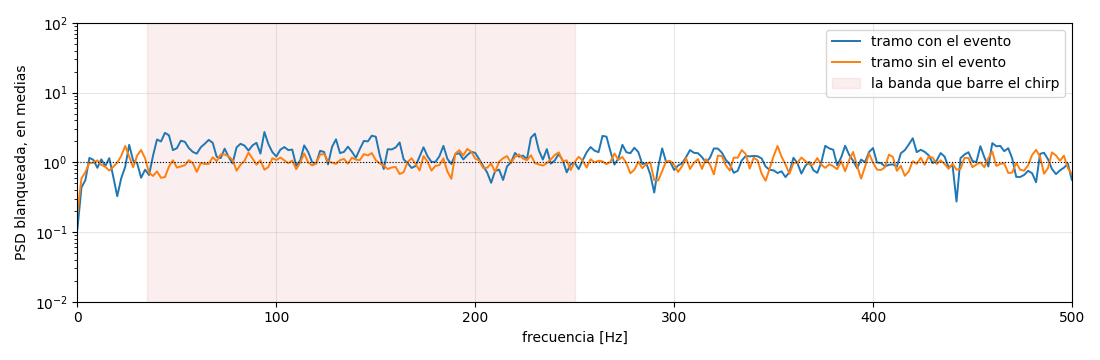

In [9]:
con_evento = np.abs(t - t_evento) < 2.0     # 4 s alrededor del evento
control = np.abs(t - (t_evento - 8)) < 2.0  # 4 s de ruido, más temprano

fig, ax = plt.subplots()
for nombre, mascara in [("tramo con el evento", con_evento), ("tramo sin el evento", control)]:
    f_w, S_w = signal.welch(h_b[mascara], fs=fs, nperseg=fs // 2)
    ax.semilogy(f_w, S_w * fs / 2, lw=1.4, label=nombre)  # fs/2: PSD en unidades de ruido blanco
ax.axhline(1, color="k", lw=0.8, ls=":")
ax.set_xlim(0, 500)
ax.set_ylim(1e-2, 1e2)
ax.set_xlabel("frecuencia [Hz]")
ax.set_ylabel("PSD blanqueada, en medias")
ax.axvspan(35, 250, alpha=0.08, color="C3", label="la banda que barre el chirp")
ax.legend()
plt.tight_layout()
plt.show()

Las dos curvas son casi la misma: planas en la banda, como corresponde a ruido blanqueado. El
chirp **no aparece** — un cuarto de segundo que barre toda la banda reparte su energía por todo
el eje, y promediado contra cuatro segundos de registro no mueve ninguna frecuencia en
particular.

No es que la información no esté: está **en la fase**, repartida entre todos los coeficientes,
ilegible a simple vista. El módulo dice *qué* hay; el *cuándo* no vive ahí.

Para un proceso WSS eso no molestaba — promediar era la gracia. El chirp no es WSS: es un
**evento**, y para verlo hace falta un análisis que también mire el tiempo.

---

## 2. El Q-scan

Un Q-scan analiza cada frecuencia $f_0$ con una ventana **a su medida**: larga en los graves,
corta en los agudos, manteniendo constante el cociente $Q = f_0/\Delta f$.
Es una teselación de $Q$ constante del plano tiempo-frecuencia.

El color mide **energía normalizada**: cada tesela dividida por la mediana de su fila, así el
ruido vale 1 en toda la banda y el número dice cuántas veces el ruido hay ahí.

Y $Q$ no se fija: se **barre** una grilla y gana el plano cuya tesela más energética es la más
alta. Ésa es la regla de la Q-transform de LIGO, y la celda la corre a la vista: imprime el
pico de cada $Q$ antes de dibujar el ganador.

Sale la figura que viste en clase, con los mismos números.

> **Predecí:** ¿qué forma va a tener el chirp en ese plano? ¿Qué $Q$ va a ganar el barrido:
> el extremo bajo de la grilla, el alto, o alguno del medio?

Q =   4.0   tesela más energética:   100 veces el ruido
Q =   5.7   tesela más energética:    97 veces el ruido
Q =   8.0   tesela más energética:    79 veces el ruido
Q =  11.3   tesela más energética:    62 veces el ruido
Q =  16.0   tesela más energética:    56 veces el ruido
Q =  22.6   tesela más energética:    59 veces el ruido
Q =  32.0   tesela más energética:    51 veces el ruido

gana Q = 4


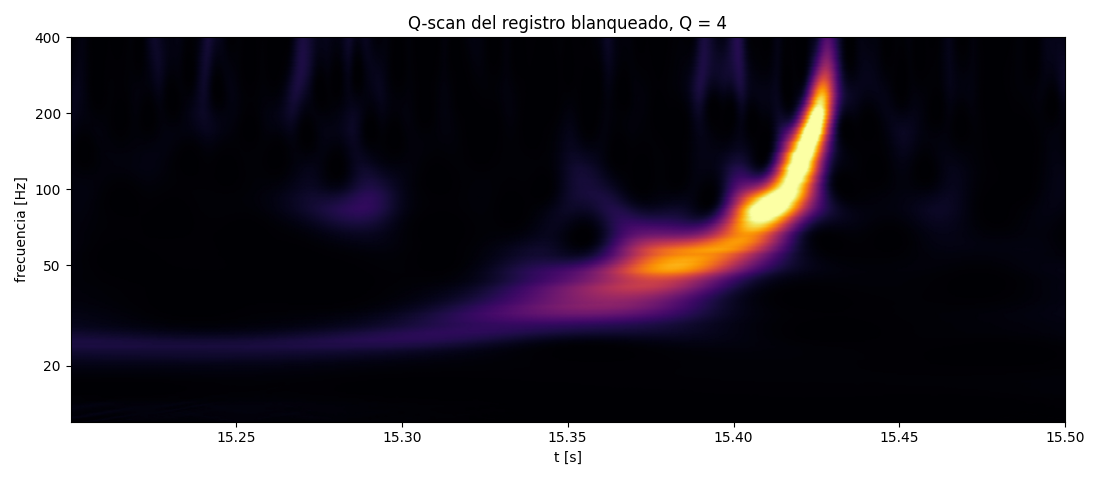

In [11]:
def qscan(x, fs, frecuencias, Q):
    """Para cada f0: correlación con una Morlet de duración sigma = Q/(2 pi f0)
    — la ventana a la medida de cada frecuencia, que es exactamente Q constante.
    Devuelve la energía normalizada: |coeficiente|^2 dividido por la mediana de
    su fila, así el ruido vale 1 en toda la banda. Filas = frecuencias."""
    plano = np.empty((len(frecuencias), len(x)))
    for i, f0 in enumerate(frecuencias):
        sigma = Q / (2 * np.pi * f0)                      # duración de la ventana
        tt = np.arange(-4 * sigma, 4 * sigma, 1 / fs)
        onda = np.exp(-(tt / sigma) ** 2 / 2) * np.exp(2j * np.pi * f0 * tt)
        onda /= np.sqrt(np.sum(np.abs(onda) ** 2))        # energía unitaria
        plano[i] = np.abs(signal.fftconvolve(x, onda.conj()[::-1], mode="same")) ** 2
    return plano / np.median(plano, axis=1, keepdims=True)


frecuencias = np.geomspace(12, 500, 300)

# Se calcula sobre 1,2 s y se mira 0,3: las medianas de la normalización necesitan
# ruido a los costados, y las colas de las Morlet de los graves duran un cuarto de
# segundo. Calculando sólo la vista, la mediana de cada fila se mediría contra el
# evento y el chirp se normalizaría a sí mismo.
ancho = np.abs(t_w - t_evento) < 0.6
x, tt = h_w[ancho], t_w[ancho]
vista = (tt > t_evento - 0.20) & (tt < t_evento + 0.10)

# Q se elige, no se fija: gana el plano con la tesela más energética.
planos = {Q: qscan(x, fs, frecuencias, Q) for Q in (4, 5.7, 8, 11.3, 16, 22.6, 32)}
for Q, plano in planos.items():
    print(f"Q = {Q:5.1f}   tesela más energética: {plano[:, vista].max():5.0f} veces el ruido")

Q = max(planos, key=lambda q: planos[q][:, vista].max())
print(f"\ngana Q = {Q}")

fig, ax = plt.subplots(figsize=(11, 4.8))
# El techo del color en 80 y no en el pico: en 40 el amarillo se derrama a los
# costados y el chirp se lee como un bloque macizo, con la frecuencia instantánea
# perdida adentro.
ax.pcolormesh(tt[vista], frecuencias, planos[Q][:, vista], cmap="inferno",
              shading="gouraud", vmin=0, vmax=80, rasterized=True)
ax.set_yscale("log")
ax.set_ylim(12, 400)          # el eje log es lo que hace que el chirp se lea
ax.set_yticks([20, 50, 100, 200, 400], ["20", "50", "100", "200", "400"])
ax.yaxis.set_minor_locator(plt.NullLocator())
ax.grid(False)
ax.set_xlabel("t [s]")
ax.set_ylabel("frecuencia [Hz]")
ax.set_title(f"Q-scan del registro blanqueado, Q = {Q}")
plt.tight_layout()
plt.show()


Ahí está: **una traza que sube**, cada vez más rápido, hasta morir cerca de los 350 Hz. El
mismo registro del experimento 1 — lo que cambió es el análisis. Y abajo de 35 Hz el campo
queda mudo: eso no es el detector, es el pasabanda de la celda de carga.

Dos cosas para llevarse. La teselación de $Q$ constante es la natural para un chirp: a cada
altura lo espera una celda a su medida, como en una partitura. Y este plano es **redundante**:
trescientas filas por cada muestra del registro, un continuo de coeficientes para reconstruir
una señal que tiene $N$ números. La clase que viene construye la versión sin redundancia — $N$
muestras, $N$ coeficientes, reconstrucción perfecta.

**Y mirá el plano de `Q = 16`**, que el barrido ya calculó: cambiá `planos[Q]` por `planos[16]`
en el `pcolormesh`. La traza se empasta — a $Q$ alto la ventana de cada frecuencia es larga, el
chirp barre *adentro* de la ventana, y volvés al problema de la ventana de 1 s del experimento
3. Por eso el barrido lo descartó, y no es una opinión: 56 veces el ruido contra 100 del
ganador.


---

## 3. Espectrograma: 10 ms, 100 ms, 1 s

La STFT tesela el plano con celdas **todas iguales**, y el largo de la ventana decide su forma:
tiempo fino y frecuencia gruesa, o al revés.

> **Predecí:** de las tres ventanas —10 ms, 100 ms, 1 s—, ¿con cuál se ve mejor el chirp?

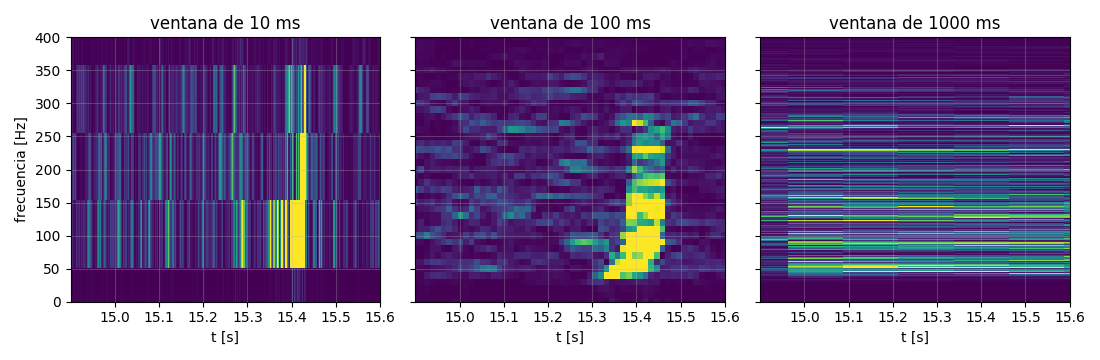

In [12]:
# la ventana de 1 s necesita señal alrededor: se calcula sobre 4 s y se hace zoom en el eje
tramo = (t_w > t_evento - 3.0) & (t_w < t_evento + 1.0)

fig, axes = plt.subplots(1, 3, figsize=(11, 3.6), sharey=True)

for ax, ancho in zip(axes, [0.010, 0.100, 1.0]):
    nper = int(ancho * fs)
    f_e, t_e, Sxx = signal.spectrogram(h_w[tramo], fs=fs, nperseg=nper,
                                       noverlap=nper * 7 // 8)
    ax.pcolormesh(t_e + t_w[tramo][0], f_e, Sxx, cmap="viridis", shading="auto",
                  vmax=np.percentile(Sxx, 99.9))
    ax.set_xlim(t_evento - 0.5, t_evento + 0.2)
    ax.set_ylim(0, 400)
    ax.set_xlabel("t [s]")
    ax.set_title(f"ventana de {1000*ancho:g} ms")

axes[0].set_ylabel("frecuencia [Hz]")
plt.tight_layout()
plt.show()

A 10 ms el tiempo es finísimo y la frecuencia un manchón: cada celda mide 100 Hz de alto. A
1 s pasa lo contrario, y algo peor: el chirp barre **doscientos hertz adentro de una sola
ventana**, así que su energía se desparrama y el trazo se empasta. La que mejor lo muestra es
la del medio — y "el medio" depende de la señal, no de la técnica.

Es el compromiso de la clase 3, otra vez: no era de Welch ni es de la STFT — es del plano.
$\Delta t \cdot \Delta f$ tiene un piso, y elegir la ventana es decidir cómo gastarlo. El
Q-scan del experimento 2 no lo esquiva: lo gasta **distinto en cada frecuencia**.

---

## 4. El banco de Haar, y su assert

El par más corto que existe: la **suma** y la **diferencia**, con su $\sqrt{2}$. Cada rama
decima —se queda con una muestra de cada dos—, así que cada rama, sola, tiene aliasing.

> **Predecí:** ¿la síntesis puede devolver la señal exacta, o solo una aproximación?

de 512 muestras salen 256 + 256: la cuenta se conserva
reconstrucción exacta: True


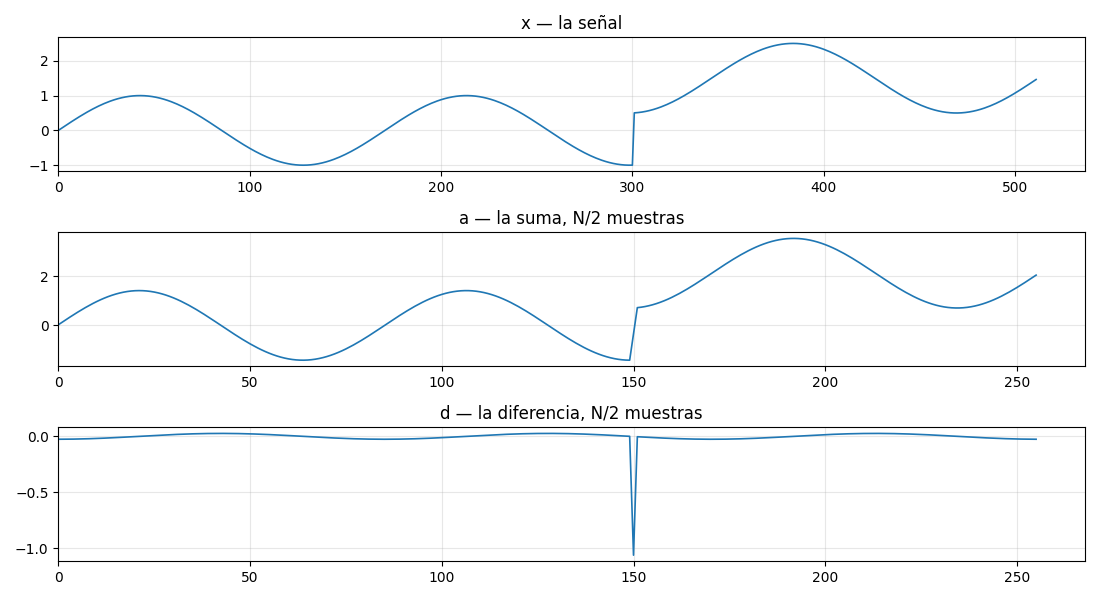

In [13]:
def analisis(x):
    """El banco de dos canales de Haar: suma y diferencia, decimados."""
    a = (x[0::2] + x[1::2]) / np.sqrt(2)
    d = (x[0::2] - x[1::2]) / np.sqrt(2)
    return a, d


def sintesis(a, d):
    x = np.empty(2 * len(a))
    x[0::2] = (a + d) / np.sqrt(2)
    x[1::2] = (a - d) / np.sqrt(2)
    return x


# una señal con las dos cosas: una parte suave y un salto
# (el salto cae adentro de un par (300|301): un salto en frontera de par
#  es invisible para la diferencia de Haar — probalo moviéndolo a 300)
n = np.arange(512)
x = np.sin(2 * np.pi * 3 * n / 512) + (n >= 301) * 1.5

a, d = analisis(x)
xr = sintesis(a, d)

print(f"de {len(x)} muestras salen {len(a)} + {len(d)}: la cuenta se conserva")
print(f"reconstrucción exacta: {np.allclose(xr, x)}")
assert np.allclose(xr, x)

fig, axes = plt.subplots(3, 1, figsize=(11, 6), sharex=False)
axes[0].plot(n, x, lw=1.2)
axes[0].set_title("x — la señal")
axes[1].plot(a, lw=1.2)
axes[1].set_title("a — la suma, N/2 muestras")
axes[2].plot(d, lw=1.2)
axes[2].set_title("d — la diferencia, N/2 muestras")
for ax in axes:
    ax.set_xlim(0, None)
plt.tight_layout()
plt.show()

`True`, muestra por muestra: **reconstrucción perfecta**, con dos ramas que por separado
tienen aliasing. Los alias de una cancelan los de la otra — la cancelación no pide filtros
buenos, y el par de Haar es todo lo tosco que un filtro puede ser.

Y mirá dónde quedó cada cosa: la parte suave vive en la suma, y el salto quedó **clavado en
la diferencia**, en la posición donde ocurrió. Eso —quedarse con la banda *y* con el cuándo— es
lo que la iteración de este banco convierte en la DWT.
